In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn
import os
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd  
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from scipy.cluster.hierarchy import linkage, dendrogram , fcluster
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid") 
plt.rcParams["figure.figsize"] = (8, 5)


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
csv_file = "Iris.csv"
df = pd.read_csv(csv_file)


df.rename(columns={
    "sepal_length": "SepalLengthCm",
    "sepal_width": "SepalWidthCm",
    "petal_length": "PetalLengthCm",
    "petal_width": "PetalWidthCm",
    "species": "Species"
}, inplace=True)


if "Id" in df.columns:
    df.drop(columns=["Id"], inplace=True)

feature_cols = [
    "SepalLengthCm", "SepalWidthCm",
    "PetalLengthCm", "PetalWidthCm"
]

required_cols = feature_cols + ["Species"]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(
        f"Missing columns: {missing_cols}. "
        "Check the CSV column names and update the column mapping."
    )


df = df.dropna(subset=required_cols).reset_index(drop=True)

X = df[feature_cols]
y_true = df["Species"].astype(str)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (150, 5)

First five records:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print("Column names:", df.columns.tolist())
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df[required_cols].isnull().sum())

print("\nStatistical summary:")
display(df[feature_cols].describe())

print("\nSpecies counts:") 
print(y_true.value_counts())

Column names: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing values:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Statistical summary:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species counts:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


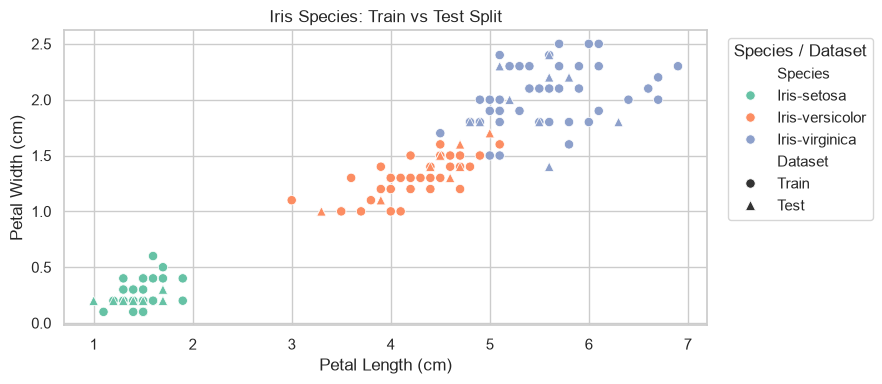

Training samples: 120
Testing samples: 30

Training species distribution:
Species
Iris-setosa        40
Iris-versicolor    40
Iris-virginica     40
Name: count, dtype: int64

Testing species distribution:
Species
Iris-setosa        10
Iris-versicolor    10
Iris-virginica     10
Name: count, dtype: int64


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y_true,
    test_size=0.20,
    random_state=42,
    stratify=y_true
)

species_list = sorted(y_true.unique())
palette = dict(zip(species_list, sns.color_palette("Set2", n_colors=len(species_list))))
markers = {"Train": "o", "Test": "^"}

train_plot = X_train[["PetalLengthCm", "PetalWidthCm"]].copy()
train_plot["Species"] = y_train.values
train_plot["Dataset"] = "Train"

test_plot = X_test[["PetalLengthCm", "PetalWidthCm"]].copy()
test_plot["Species"] = y_test.values
test_plot["Dataset"] = "Test"

split_plot = pd.concat([train_plot, test_plot], ignore_index=True)

plt.figure(figsize=(9, 4))
sns.scatterplot(
    data=split_plot,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    style="Dataset",
    hue_order=species_list,
    style_order=["Train", "Test"],
    markers=markers,
    palette=palette,
    s=45
)
plt.title("Iris Species: Train vs Test Split")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Species / Dataset", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining species distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting species distribution:")
print(y_test.value_counts().sort_index())

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized feature sample:")
display(pd.DataFrame(X_scaled, columns=feature_cols).head())

Standardized feature sample:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


In [6]:
def dunn_index(X, labels):
    # Calculate distances between all pairs of data points
    distances = pairwise_distances(X)

    unique_clusters = np.unique(labels)

    # Find the maximum diameter within any cluster
    max_cluster_diameter = 0

    for cluster in unique_clusters:
        indices = np.where(labels == cluster)[0]
        cluster_distances = distances[np.ix_(indices, indices)]

        diameter = np.max(cluster_distances)

        max_cluster_diameter = max(
            max_cluster_diameter, diameter
        )

    # Find the minimum distance between different clusters
    min_intercluster_distance = np.inf

    for i in range(len(unique_clusters)):
        for j in range(i + 1, len(unique_clusters)):
            cluster_i = np.where(
                labels == unique_clusters[i]
            )[0]

            cluster_j = np.where(
                labels == unique_clusters[j]
            )[0]

            inter_distances = distances[
                np.ix_(cluster_i, cluster_j)
            ]

            min_distance = np.min(inter_distances)

            min_intercluster_distance = min(
                min_intercluster_distance, min_distance
            )

    # Calculate Dunn Index
    if max_cluster_diameter == 0:
        return np.inf if min_intercluster_distance > 0 else 0

    return min_intercluster_distance / max_cluster_diameter

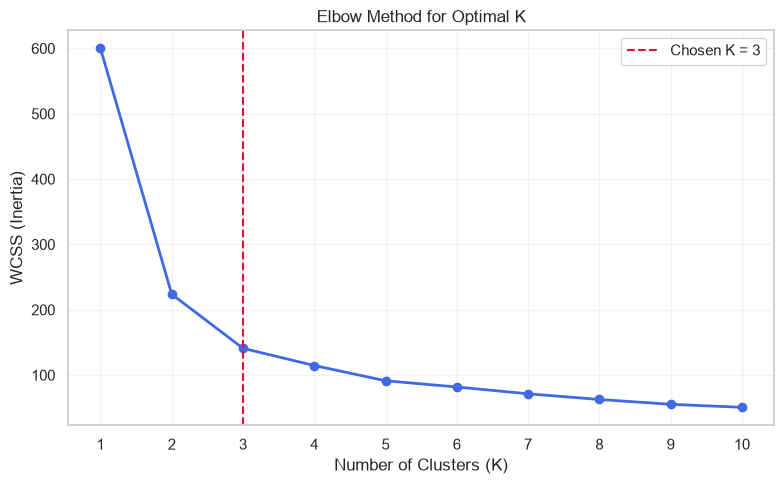

In [7]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker="o", color="royalblue", linewidth=2)
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(list(K_range))
plt.axvline(x=3, color="crimson", linestyle="--", label="Chosen K = 3")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

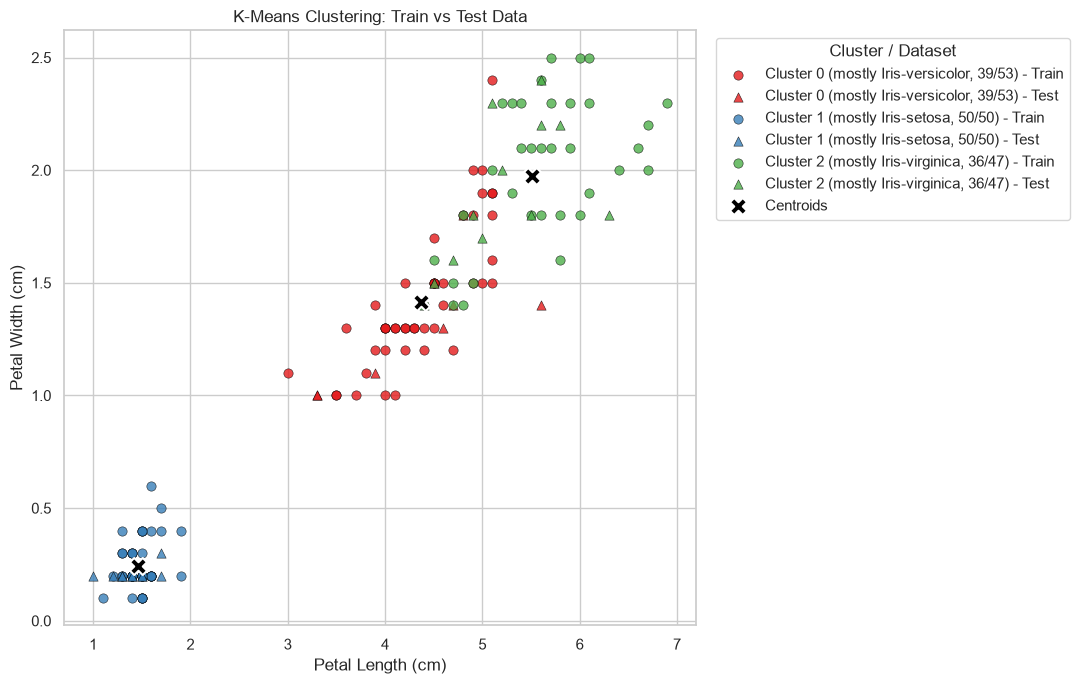

K-Means cluster sizes:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

K-Means Dunn Index: 0.026


In [8]:

k = 3

kmeans = KMeans(
    n_clusters=k,
    init="k-means++",
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# Mark which rows belong to training and testing sets.
df["Dataset"] = "Train"
df.loc[X_test.index, "Dataset"] = "Test"

# Generate informative cluster labels using the actual species.
kmeans_cluster_labels = {}

for cluster_id in sorted(df["KMeans_Cluster"].unique()):
    subset = df[df["KMeans_Cluster"] == cluster_id]

    dominant_species = subset["Species"].mode().iloc[0]
    matches = (subset["Species"] == dominant_species).sum()
    total = len(subset)

    kmeans_cluster_labels[cluster_id] = (
        f"Cluster {cluster_id} (mostly {dominant_species}, "
        f"{matches}/{total})"
    )

# Convert centroid coordinates to original measurements.
centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

# Create consistent colors for the clusters.
cluster_colors = sns.color_palette("Set1", n_colors=k)

plt.figure(figsize=(11, 7))

for cluster_id in sorted(df["KMeans_Cluster"].unique()):
    for dataset_name, marker in [("Train", "o"), ("Test", "^")]:
        subset = df[
            (df["KMeans_Cluster"] == cluster_id) &
            (df["Dataset"] == dataset_name)
        ]

        plt.scatter(
            subset["PetalLengthCm"],
            subset["PetalWidthCm"],
            color=cluster_colors[cluster_id],
            marker=marker,
            s=45,
            alpha=0.8,
            edgecolors="black",
            linewidths=0.4,
            label=(
                f"{kmeans_cluster_labels[cluster_id]} - "
                f"{dataset_name}"
            )
        )

# Plot cluster centroids.
plt.scatter(
    centroids_original[:, 2],
    centroids_original[:, 3],
    marker="X",
    s=150,
    c="black",
    edgecolors="white",
    linewidths=1.5,
    label="Centroids",
    zorder=5
)

plt.title("K-Means Clustering: Train vs Test Data")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(
    title="Cluster / Dataset",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

print("K-Means cluster sizes:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print(
    "\nK-Means Dunn Index:",
    round(dunn_index(X_scaled, df["KMeans_Cluster"]), 3)
)



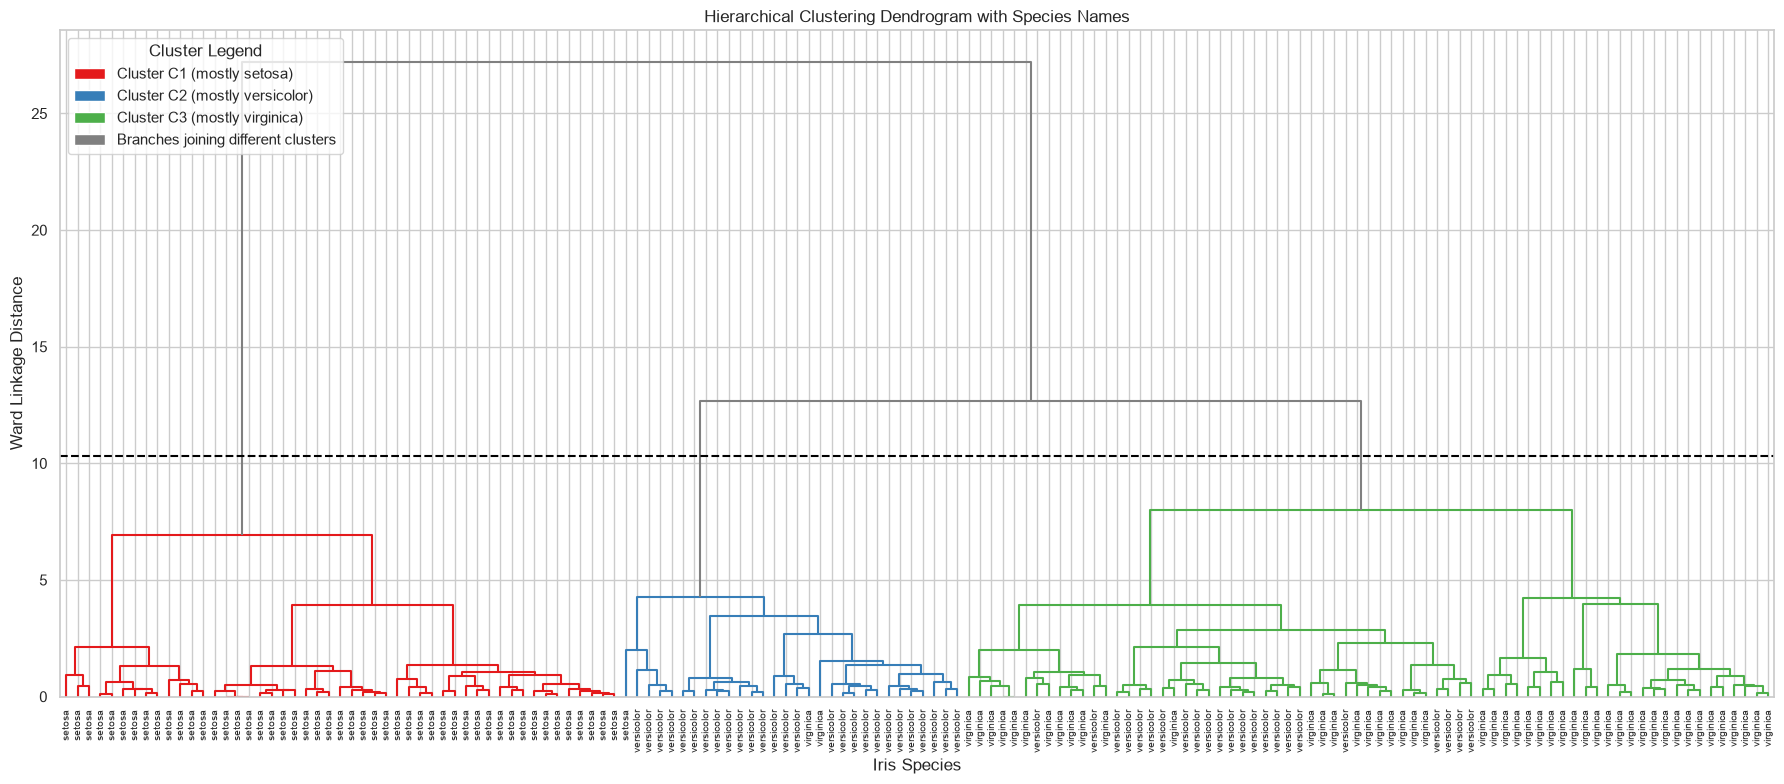

In [16]:

linked = linkage(X_scaled, method="ward")

threshold = (linked[-3, 2] + linked[-2, 2]) / 2

dendro_clusters = fcluster(
    linked,
    t=threshold,
    criterion="distance"
)

cluster_ids = sorted(set(dendro_clusters))

colors = sns.color_palette(
    "Set1",
    n_colors=len(cluster_ids)
).as_hex()

cluster_color_map = {
    cluster_id: colors[i]
    for i, cluster_id in enumerate(cluster_ids)
}

n_samples = len(df)

node_members = {
    i: {i}
    for i in range(n_samples)
}

for i, row in enumerate(linked):
    left = int(row[0])
    right = int(row[1])

    node_members[n_samples + i] = (
        node_members[left] | node_members[right]
    )

def branch_color(node_id):
    members = node_members[node_id]

    member_clusters = {
        dendro_clusters[i]
        for i in members
    }

    if len(member_clusters) == 1:
        cluster_id = next(iter(member_clusters))
        return cluster_color_map[cluster_id]

    return "grey"

leaf_labels = (
    df["Species"]
    .astype(str)
    .str.replace("Iris-", "", regex=False)
    .tolist()
)

plt.figure(figsize=(18, 8))

dendrogram(
    linked,
    labels=leaf_labels,
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=threshold,
    above_threshold_color="grey",
    link_color_func=branch_color
)

plt.axhline(
    y=threshold,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"3-cluster cut (distance = {threshold:.2f})"
)

plt.title("Hierarchical Clustering Dendrogram with Species Names")
plt.xlabel("Iris Species")
plt.ylabel("Ward Linkage Distance")



legend_items = [
    Patch(
        facecolor=cluster_color_map[cid],
        label=f"Cluster C{cid} (mostly {df.loc[dendro_clusters == cid, 'Species'].mode().iloc[0].replace('Iris-', '')})"
    )
    for cid in cluster_ids
]

legend_items.append(
    Patch(facecolor="grey", label="Branches joining different clusters")
)

plt.legend(handles=legend_items, title="Cluster Legend", loc="upper left")

plt.tight_layout()
plt.show()


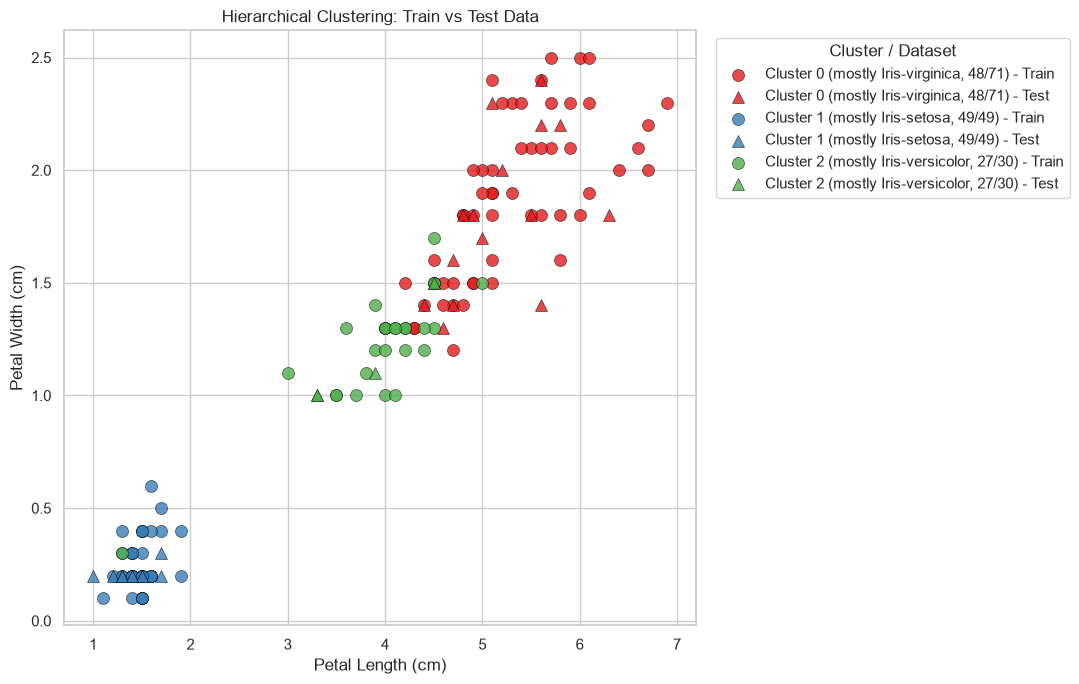

Hierarchical cluster sizes:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64

Hierarchical Dunn Index: 0.098


In [10]:

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

# Keep the same train/test distinction as Cell 6.
df["Dataset"] = "Train"
df.loc[X_test.index, "Dataset"] = "Test"

# Generate informative cluster labels.
hier_cluster_labels = {}

for cluster_id in sorted(df["Hierarchical_Cluster"].unique()):
    subset = df[df["Hierarchical_Cluster"] == cluster_id]
    dominant_species = subset["Species"].mode().iloc[0]
    matches = (subset["Species"] == dominant_species).sum()
    total = len(subset)

    hier_cluster_labels[cluster_id] = (
        f"Cluster {cluster_id} (mostly {dominant_species}, "
        f"{matches}/{total})"
    )

cluster_colors = sns.color_palette("Set1", n_colors=3)

plt.figure(figsize=(11, 7))

for cluster_id in sorted(df["Hierarchical_Cluster"].unique()):
    for dataset_name, marker in [("Train", "o"), ("Test", "^")]:
        subset = df[
            (df["Hierarchical_Cluster"] == cluster_id) &
            (df["Dataset"] == dataset_name)
        ]

        plt.scatter(
            subset["PetalLengthCm"],
            subset["PetalWidthCm"],
            color=cluster_colors[cluster_id],
            marker=marker,
            s=75,
            alpha=0.8,
            edgecolors="black",
            linewidths=0.4,
            label=(
                f"{hier_cluster_labels[cluster_id]} - "
                f"{dataset_name}"
            )
        )

plt.title("Hierarchical Clustering: Train vs Test Data")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(
    title="Cluster / Dataset",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

print("Hierarchical cluster sizes:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

print(
    "\nHierarchical Dunn Index:",
    round(
        dunn_index(X_scaled, df["Hierarchical_Cluster"]),
        3
    )
)


In [11]:
print("K-Means: average measurements in each cluster")
display(
    df.groupby("KMeans_Cluster")[feature_cols]
      .mean()
      .round(2)
)

print("Hierarchical: average measurements in each cluster")
display(
    df.groupby("Hierarchical_Cluster")[feature_cols]
      .mean()
      .round(2)
)

K-Means: average measurements in each cluster


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
KMeans_Cluster,,,,
0,5.80,2.67,4.37,1.41
1,5.01,3.42,1.46,0.24
2,6.78,3.10,5.51,1.97


Hierarchical: average measurements in each cluster


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Hierarchical_Cluster,,,,
0,6.55,2.99,5.27,1.85
1,5.02,3.44,1.47,0.24
2,5.53,2.57,3.93,1.21


In [12]:
print("K-Means clusters vs actual species:")
display(pd.crosstab(df["KMeans_Cluster"], df["Species"]))

print("Hierarchical clusters vs actual species:")
display(pd.crosstab(df["Hierarchical_Cluster"], df["Species"]))

K-Means clusters vs actual species:


Species,Iris-setosa,Iris-versicolor,Iris-virginica
KMeans_Cluster,,,
0,0,39,14
1,50,0,0
2,0,11,36


Hierarchical clusters vs actual species:


Species,Iris-setosa,Iris-versicolor,Iris-virginica
Hierarchical_Cluster,,,
0,0,23,48
1,49,0,0
2,1,27,2


Clustering Method Comparison using Dunn Index:


,Method,Dunn Index
0,K-Means,0.0264
1,Hierarchical Agglomerative,0.0980


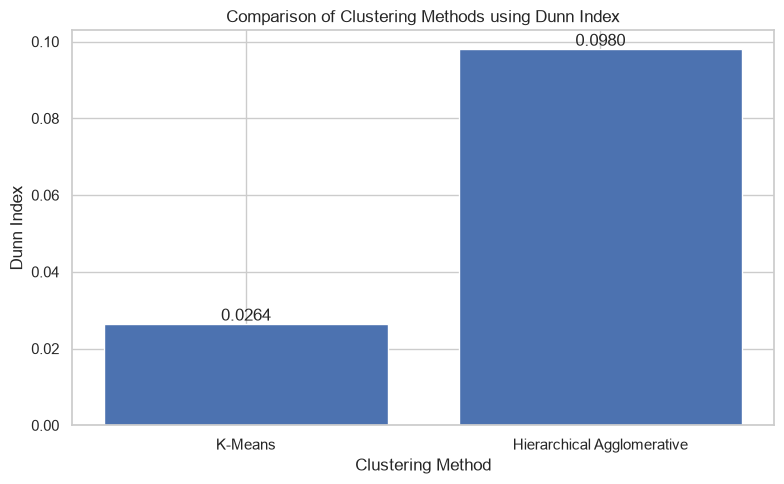

In [13]:
# Calculate Dunn Index for both clustering methods
kmeans_dunn = dunn_index(
    X_scaled,
    df["KMeans_Cluster"].values
)

hierarchical_dunn = dunn_index(
    X_scaled,
    df["Hierarchical_Cluster"].values
)

# Create comparison table
comparison_df = pd.DataFrame({
    "Method": [
        "K-Means",
        "Hierarchical Agglomerative"
    ],
    "Dunn Index": [
        kmeans_dunn,
        hierarchical_dunn
    ]
})

print("Clustering Method Comparison using Dunn Index:")
display(comparison_df.round(4))

# Plot the comparison
plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison_df["Method"],
    comparison_df["Dunn Index"]
)

plt.title("Comparison of Clustering Methods using Dunn Index")
plt.xlabel("Clustering Method")
plt.ylabel("Dunn Index")

# Show values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [14]:
print("========== FINAL RESULT ==========")
print("Dataset: Iris")
print("Number of records:", len(df))
print("Number of numerical features:", len(feature_cols))
print("Number of clusters used:", 3)
print("K-Means clustering completed successfully.")
print("Hierarchical clustering completed successfully.")
print("Elbow graph, dendrogram, centroid plot, cluster plots, and train/test species plot generated.")

========== FINAL RESULT ==========
Dataset: Iris
Number of records: 150
Number of numerical features: 4
Number of clusters used: 3
K-Means clustering completed successfully.
Hierarchical clustering completed successfully.
Elbow graph, dendrogram, centroid plot, cluster plots, and train/test species plot generated.
